# Lab Practice: Comparing Linear and Nonlinear Regression Models for Food Delivery Time Prediction

## Lab Objectives

In this lab, students will:

1. Understand the dataset and identify the **target variable** and **input features**.
2. Perform **data preprocessing** and handle missing values.
3. Encode **categorical features** into numerical values.
4. Explore the relationships between variables using data visualization.
5. Split the dataset into **training** and **testing** sets.
6. Train a **Multiple Linear Regression** model.
7. Evaluate model performance using **Root Mean Squared Error (RMSE)** and other evaluation metrics.
8. Train a **Decision Tree Regressor** to capture nonlinear relationships.
9. Compare model performance using RMSE and R².
10. Explain when nonlinear models are preferred over linear models.

## I. Dataset

### 1. About the Dataset
This dataset is designed to predict **food delivery time** based on various influencing factors such as distance, weather conditions, traffic conditions, and time of day. It provides a practical machine learning problem related to logistics and operations.

**Dataset Source:**  
https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction/data


### 2. Download the Dataset

**Instructions:**
1. Visit the dataset source above.
2. Download the dataset from Kaggle.

**Task:**  
Write Python code to load the dataset and display the first 5 rows.


In [3]:
# TODO: Import required libraries
# Example: pandas, numpy
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [4]:
# TODO: Load dataset
# Hint: Use pd.read_csv()
df = pd.read_csv('../dataset/Food_Delivery_Times.csv')  


In [5]:
# TODO: Display first 5 rows of the dataset
df.head()


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## II. Data Understanding

### Task 1: Explore Dataset Information

**Instructions:**
- Check the number of rows and columns.
- View dataset information.
- Check data types of each feature.


In [6]:
# TODO: Display dataset shape
print(df.shape)


(1000, 9)


In [7]:
# TODO: Show dataset information
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 91.3 KB
None


In [8]:
# TODO: Display data types
print(df.dtypes)


Order_ID                    int64
Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object


### Task 2: Identify Features and Target Variable

**Question:**
- Which column should be used as the **target variable (output)**?
- Which columns should be used as **input features**?


In [9]:
# TODO: Define features (X) and target variable (y)
X = df.drop('Delivery_Time_min', axis=1)  # Features
y = df['Delivery_Time_min']  # Target variable


## III. Data Preprocessing

### Task 1: Check Missing Values

**Instructions:**
- Identify missing values in the dataset.
- Decide how to handle missing values.


In [10]:
# TODO: Check missing values
print(df.isnull().sum())
if df.isnull().sum().any():
    print("Missing values found. Consider handling them before model training.")
else:
    print("No missing values found. Proceeding with model training.")


Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64
Missing values found. Consider handling them before model training.


### Task 2: Handle Categorical Features

**Instructions:**
- Identify categorical columns.
- Convert categorical values into numerical values using encoding.

**Hint:**  
You may use:
- Label Encoding
- One-Hot Encoding


In [11]:
# TODO: Identify categorical columns
categorical_columns = X.select_dtypes(include=['object']).columns
print("Categorical columns:", categorical_columns)


Categorical columns: Index(['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type'], dtype='str')


C:\Users\U-ser\AppData\Local\Temp\ipykernel_9080\4195546986.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=['object']).columns


In [12]:
# TODO: Encode categorical features
one_hot_encoded_columns = pd.get_dummies(X[categorical_columns], drop_first=True)
X = pd.concat([X.drop(categorical_columns, axis=1), one_hot_encoded_columns], axis=1)
print("Features after encoding:")
print(X.head())

Features after encoding:
   Order_ID  Distance_km  Preparation_Time_min  Courier_Experience_yrs  \
0       522         7.93                    12                     1.0   
1       738        16.42                    20                     2.0   
2       741         9.52                    28                     1.0   
3       661         7.44                     5                     1.0   
4       412        19.03                    16                     5.0   

   Weather_Foggy  Weather_Rainy  Weather_Snowy  Weather_Windy  \
0          False          False          False           True   
1          False          False          False          False   
2           True          False          False          False   
3          False           True          False          False   
4          False          False          False          False   

   Traffic_Level_Low  Traffic_Level_Medium  Time_of_Day_Evening  \
0               True                 False                False   
1    

### Task 3 (Optional): Feature Scaling / Normalization

**Instructions:**
Normalize numerical features if necessary.


In [13]:
# TODO: Normalize numerical features (Optional)
normalization_columns = X.select_dtypes(include=[np.number]).columns
X[normalization_columns] = (X[normalization_columns] - X[normalization_columns].mean()) / X[normalization_columns].std()
print("Features after normalization:")
print(X.head())


Features after normalization:
   Order_ID  Distance_km  Preparation_Time_min  Courier_Experience_yrs  \
0  0.074441    -0.373898             -0.691507               -1.228174   
1  0.822313     1.116450              0.418902               -0.885049   
2  0.832700    -0.094787              1.529311               -1.228174   
3  0.555711    -0.459914             -1.663115               -1.228174   
4 -0.306420     1.574613             -0.136303                0.144325   

   Weather_Foggy  Weather_Rainy  Weather_Snowy  Weather_Windy  \
0          False          False          False           True   
1          False          False          False          False   
2           True          False          False          False   
3          False           True          False          False   
4          False          False          False          False   

   Traffic_Level_Low  Traffic_Level_Medium  Time_of_Day_Evening  \
0               True                 False                False   


## IV. Exploratory Data Analysis (EDA)

### Task 1: Correlation Analysis

**Instructions:**
Create a correlation heatmap to identify which features have strong relationships with delivery time.



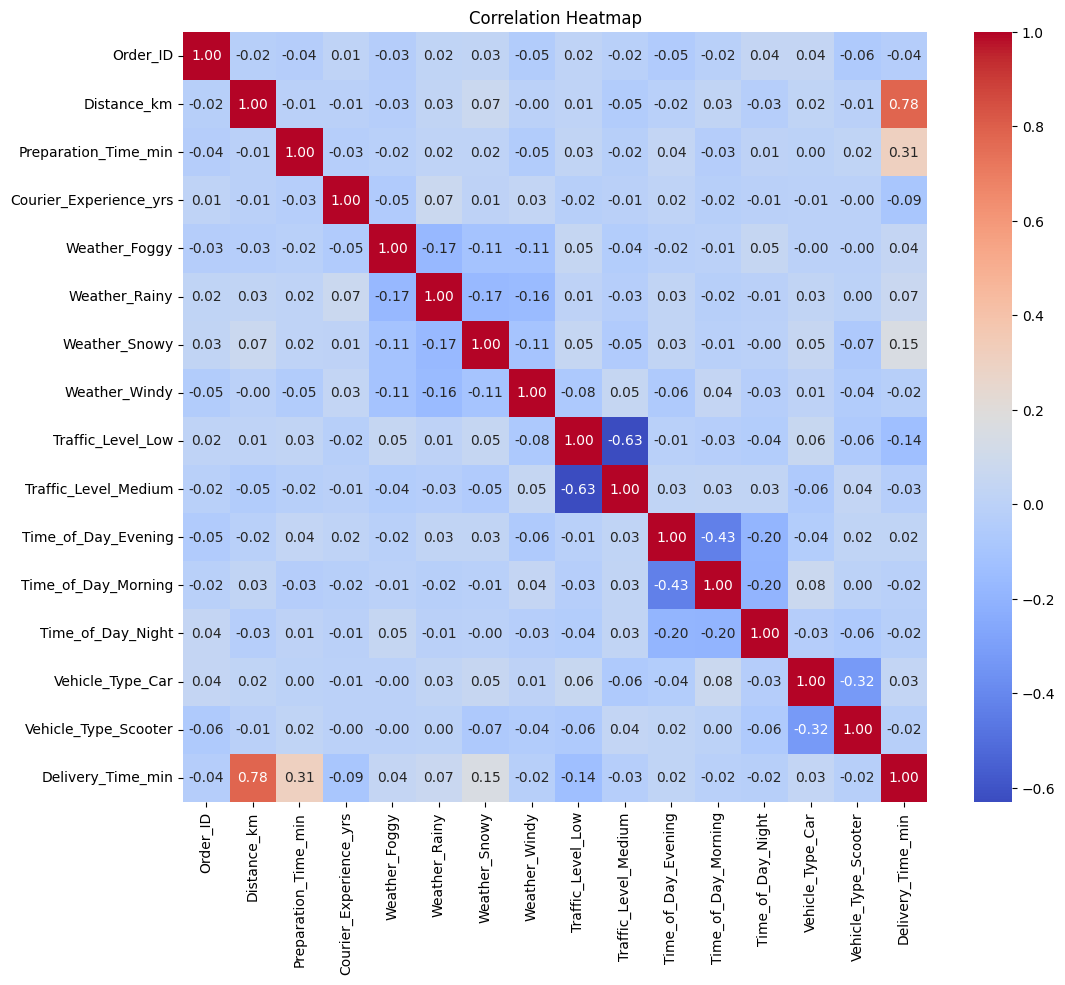

In [14]:
# TODO: Plot correlation heatmap
df_full = pd.concat([X, y], axis=1)
plt.figure(figsize=(12, 10))
sns.heatmap(df_full.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


### Task 2: Feature Selection (Optional)

**Instructions:**
Based on the correlation results, you may remove features that appear to have little influence on prediction performance.


In [15]:
# TODO: Drop unnecessary features (Optional)
# 'Order_ID' is an identifier and does not affect prediction.
df = df.drop(columns=['Order_ID'], errors='ignore')
X = X.drop(columns=['Order_ID'], errors='ignore')
print("Dropped 'Order_ID'. New feature set shape:", X.shape)
print(X.columns.tolist())

Dropped 'Order_ID'. New feature set shape: (1000, 14)
['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Weather_Foggy', 'Weather_Rainy', 'Weather_Snowy', 'Weather_Windy', 'Traffic_Level_Low', 'Traffic_Level_Medium', 'Time_of_Day_Evening', 'Time_of_Day_Morning', 'Time_of_Day_Night', 'Vehicle_Type_Car', 'Vehicle_Type_Scooter']


## V. Split Dataset

### Train-Test Split

**Instructions:**
Split the dataset into:
- **Training set**: used to train the model
- **Testing set**: used to evaluate model performance

**Recommended split ratio:** 80% training and 20% testing


In [16]:
# TODO: Split dataset into train and test sets
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set shape:", x_train.shape)
print("Test set shape:", x_test.shape)

Training set shape: (800, 14)
Test set shape: (200, 14)


## VI. Nonlinear Modeling with Decision Trees

### Why Use Decision Trees?

Decision Trees can model nonlinear relationships that Multiple Linear Regression cannot easily capture.

**Advantages**
- Capture nonlinear patterns
- Handle feature interactions automatically
- Easy to visualize and interpret
- Require little preprocessing

### What Can Decision Trees Handle?
- Delivery time prediction
- House price prediction
- Clothing size prediction
- Customer spending prediction


## VII. Build Three Regression Models

Train and compare the following models:

1. Multiple Linear Regression (Baseline)
2. Decision Tree Regressor

Use the same train-test split for all models.


In [17]:
# TODO: Import models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [18]:
# TODO: Train Multiple Linear Regression model
# Handle NaNs by dropping rows with missing values before training
train_data = pd.concat([x_train, y_train], axis=1).dropna()
x_train_clean = train_data.drop('Delivery_Time_min', axis=1)
y_train_clean = train_data['Delivery_Time_min']

linear_model = LinearRegression()
linear_model.fit(x_train_clean, y_train_clean)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](14,)","[17.1 , 6.95,-1.96,...,-2.21, 0.54,-0.96]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](14,)","['Distance_km','Preparation_Time_min','Courier_Experience_yrs',..., 'Time_of_Day_Night','Vehicle_Type_Car','Vehicle_Type_Scooter']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.12
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,14


In [19]:
# TODO: Train Decision Tree Regressor
# Suggested:
dt_model = DecisionTreeRegressor(max_depth=5, random_state=42)
dt_model.fit(x_train_clean, y_train_clean)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

## VI. Build Multiple Linear Regression Model

### Task: Train the Model

**Instructions:**
Train a **Multiple Linear Regression** model using the training data.

- Mathematical Form

$$
y = b_0 + b_1x_1 + b_2x_2 + b_3x_3 + \cdots + b_nx_n
$$

Where:

 - $y$ = predicted target value (Delivery Time)
 - $b_0$ = intercept (constant)
 - $b_1, b_2, ..., b_n$ = coefficients (weights)
 - $x_1, x_2, ..., x_n$ = input features
  

- Supporting resource for model: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

In [20]:
# TODO: Import regression model
from sklearn.linear_model import LinearRegression

In [21]:
# TODO: Train the model
#remove Nan
train_data = pd.concat([x_test, y_test], axis=1).dropna()
x_test_clean = train_data.drop('Delivery_Time_min', axis=1)
y_test_clean = train_data['Delivery_Time_min']

# Train Linear Regression model using training data
lr_model = LinearRegression()
lr_model.fit(x_test_clean, y_test_clean)

print("Coefficients:", lr_model.coef_)
print("Intercept:", lr_model.intercept_)

Coefficients: [ 16.45877678   6.8572561   -1.73383394  13.99780558   5.227001
  10.53891112   4.76676952 -13.78161502  -8.15649519  -0.57016347
  -1.15910523   1.08210063   0.66473542  -0.82213292]
Intercept: 61.07634793217145


## VII. Model Prediction

### Task: Make Predictions

**Instructions:**
Use the trained model to predict delivery time for the testing dataset.


In [22]:
# TODO: Predict test data
# Predict delivery time for testing dataset
y_pred_lr = lr_model.predict(x_test_clean)

print("Predicted Delivery Times:")
print(y_pred_lr)


Predicted Delivery Times:
[31.78716713 70.23304907 44.65688066 40.29755152 78.81622224 30.60992475
 74.92959808 33.63284722 46.80013558 84.90361631 70.26854466 55.96847584
 44.84124262 73.6627908  85.32693684 81.96316494 29.48735038 65.76568398
 45.58846573 63.79902058 78.56072857 26.32880478 80.08586964 80.36680329
 60.37387279 32.77546454 84.80646605 23.03389478 46.9508413  62.83086013
 77.23755593 15.24868566 65.6173245  38.81540977 64.26530702 17.6682121
 59.57654622 51.08781053 53.26114785 75.13636649 71.48388101 29.65788711
 78.7039537  71.12621985 34.95628444 13.16730724 91.83333789 79.08695575
 74.92279831 25.03194507 73.98424099 53.52203261 34.87500577 78.5808285
 55.85485291 50.28698919 81.36165121 80.32478466 66.08909665 97.05928084
 54.61001879 37.05403168 58.44379136 45.70805922 52.37988933 67.70717256
 58.68565133 89.69483189 76.71336842 58.71523424 82.76091986 35.97796592
 90.18329496 22.94508001 61.12341318 58.8765691  40.76865828 45.71730296
 53.01316664 61.60217293 69

## VIII. Model Evaluation

### Task: Evaluate Model Performance

**Instructions:**
Evaluate model performance using:
- Root Mean Squared Error (**RMSE**)
- R² Score

In [23]:
# TODO: Evaluate model performance
from sklearn.metrics import mean_squared_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test_clean, y_pred_lr))
r2_lr = r2_score(y_test_clean, y_pred_lr)

print(f"Linear Regression RMSE: {rmse:.4f}")
print(f"Linear Regression R2: {r2_lr:.4f}")

Linear Regression RMSE: 8.2975
Linear Regression R2: 0.8467


## IX. Reflection Questions

Answer the following questions:

1. What is the target variable in this dataset?
2. Which features most strongly affect food delivery time?
3. Why is data preprocessing important before training a model?
4. Why do categorical variables need encoding?
5. What does RMSE tell us about model performance?


1. The target variable in this dataset is 'Delivery_Time_min', which represents the delivery time in minutes.
2. The features the most strongly affect food delivery time is 'Distance_km'.
3. Data preprocessing important before training a model because it improves model performace by handling missing values.
4. Categorical variables need encoding because machine learning models require numerical input.
5. RMSE (Root Mean Squared Error) measures the average prediction error in the unit as the target variables, where lower value indicate better performace.

## X. Model Evaluation and Comparison

Evaluate all three models using:

- MAE (Mean Absolute Error)
- RMSE (Root Mean Squared Error)
- R² Score

Create a comparison table:

| Model | MAE | RMSE | R² |
|---------|---------|---------|---------|
| Multiple Linear Regression |5.8147 |8.2975 |0.8467 |
| Decision Tree |9.0826 |12.2889 |0.6638 |
| Random Forest |3.0894 |4.3406 |0.9581 |


In [24]:
# TODO: Calculate RMSE and R² for all models
lr_model_rmse = np.sqrt(mean_squared_error(y_test_clean, y_pred_lr))
lr_model_r2 = r2_score(y_test_clean, y_pred_lr)
lr_model_mae = mean_absolute_error(y_test_clean, y_pred_lr)
print(f"Linear Regression RMSE: {lr_model_rmse:.4f}")
print(f"Linear Regression R²: {lr_model_r2:.4f}")
print(f"Linear Regression MAE: {lr_model_mae:.4f}")

dt_model_rmse = np.sqrt(mean_squared_error(y_test_clean, dt_model.predict(x_test_clean)))
dt_model_r2 = r2_score(y_test_clean, dt_model.predict(x_test_clean))
dt_model_mae = mean_absolute_error(y_test_clean, dt_model.predict(x_test_clean))
print(f"Decision Tree RMSE: {dt_model_rmse:.4f}")
print(f"Decision Tree R²: {dt_model_r2:.4f}")
print(f"Decision Tree MAE: {dt_model_mae:.4f}")

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_test_clean, y_test_clean)
rf_model_rmse = np.sqrt(mean_squared_error(y_test_clean, rf_model.predict(x_test_clean)))
rf_model_r2 = r2_score(y_test_clean, rf_model.predict(x_test_clean))                     
rf_model_mae = mean_absolute_error(y_test_clean, rf_model.predict(x_test_clean))
print(f"Random Forest RMSE: {rf_model_rmse:.4f}")
print(f"Random Forest R²: {rf_model_r2:.4f}")
print(f"Random Forest MAE: {rf_model_mae:.4f}")

Linear Regression RMSE: 8.2975
Linear Regression R²: 0.8467
Linear Regression MAE: 5.8147
Decision Tree RMSE: 12.2889
Decision Tree R²: 0.6638
Decision Tree MAE: 9.0826
Random Forest RMSE: 4.3406
Random Forest R²: 0.9581
Random Forest MAE: 3.0894


## XI. Reflection Questions

1. Which model achieved the highest R² score?
2. Which model had the lowest RMSE?
3. Did the Decision Tree outperform Multiple Linear Regression?



1. Random Forest model achieved the highest R² score, best overall fit to the data.
2. Random Forest model had the lowest RMSE of 4.3406
3. The decision Tree did not outperform Multiple Linear Regression as it have a lower R² score and a higher RSME.